# 3.3 Domínio da frequência

FFT das mesmas janelas da análise temporal (notebook 2) e espectros de magnitude, saudável × defeituosa

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.io_utils import ler_acc
from src.windowing import get_matriz_acc

In [2]:
from scipy.signal import find_peaks

from src.freq_features import espectro, feat_espectrais, BANDAS, FS

list_janelas = pd.read_csv("../data/processed/janelas.csv")

# FS tem que ser igual ao fs_acc (calculado de t) e ao samplingRate declarado, em todos os registros
registros = pd.read_csv("../results/tables/registros.csv")
assert np.isclose(registros["fs_acc"], FS).all() and (registros["fs_acc_decl"] == FS).all()
print(f"FS = {FS} Hz confere com fs_acc e fs_acc_decl em {len(registros)} registros")

# um par por SP: mesmo C (C1), mesma duração, saudável × defeituosa de maior severidade
ARQ = {sp: {"saudavel": f"F0_SV0_SP{sp}_C1_R1.mat", "defeituoso": f"F1_SV3_SP{sp}_C1.mat"}
       for sp in [1, 2, 3]}
ROT = {"saudavel": "saudável", "defeituoso": "defeituosa"}
CORES = {"saudavel": "tab:blue", "defeituoso": "tab:red"}
# janela 10 = trecho de 20 a 22 s
JAN = 10

FS = 10000 Hz confere com fs_acc e fs_acc_decl em 111 registros


## Convenções e registros

Mesma função `espectro` (`src/freq_features.py`) para todas as janelas:

- média subtraída de cada janela (tira a componente de 0 Hz);
- janela de Hann, reduz o vazamento espectral;
- `rfft`: o sinal é real, então basta de 0 a fs/2;
- magnitude = 2·abs(X) / soma(janela)
- eixo f[k] = k·fs/N: com N = 20000 e fs = 10 kHz, Δf = 0,5 Hz e vai até 5000 Hz.

`fs = 10000` Hz vem de `fs_acc` em `registros.csv` (igual ao `samplingRate` nos 111 registros). A célula de setup confere isso com um `assert`.

In [3]:
espectros = {}
for sp, par in ARQ.items():
    for cond, arquivo in par.items():
        f, mag = espectro(get_matriz_acc(arquivo, list_janelas)[JAN], FS)
        espectros[(sp, cond)] = mag[0]

print(f"f: {f.shape} | passo {f[1] - f[0]} Hz | até {f[-1]:.0f} Hz")

f: (10001,) | passo 0.5 Hz | até 5000 Hz


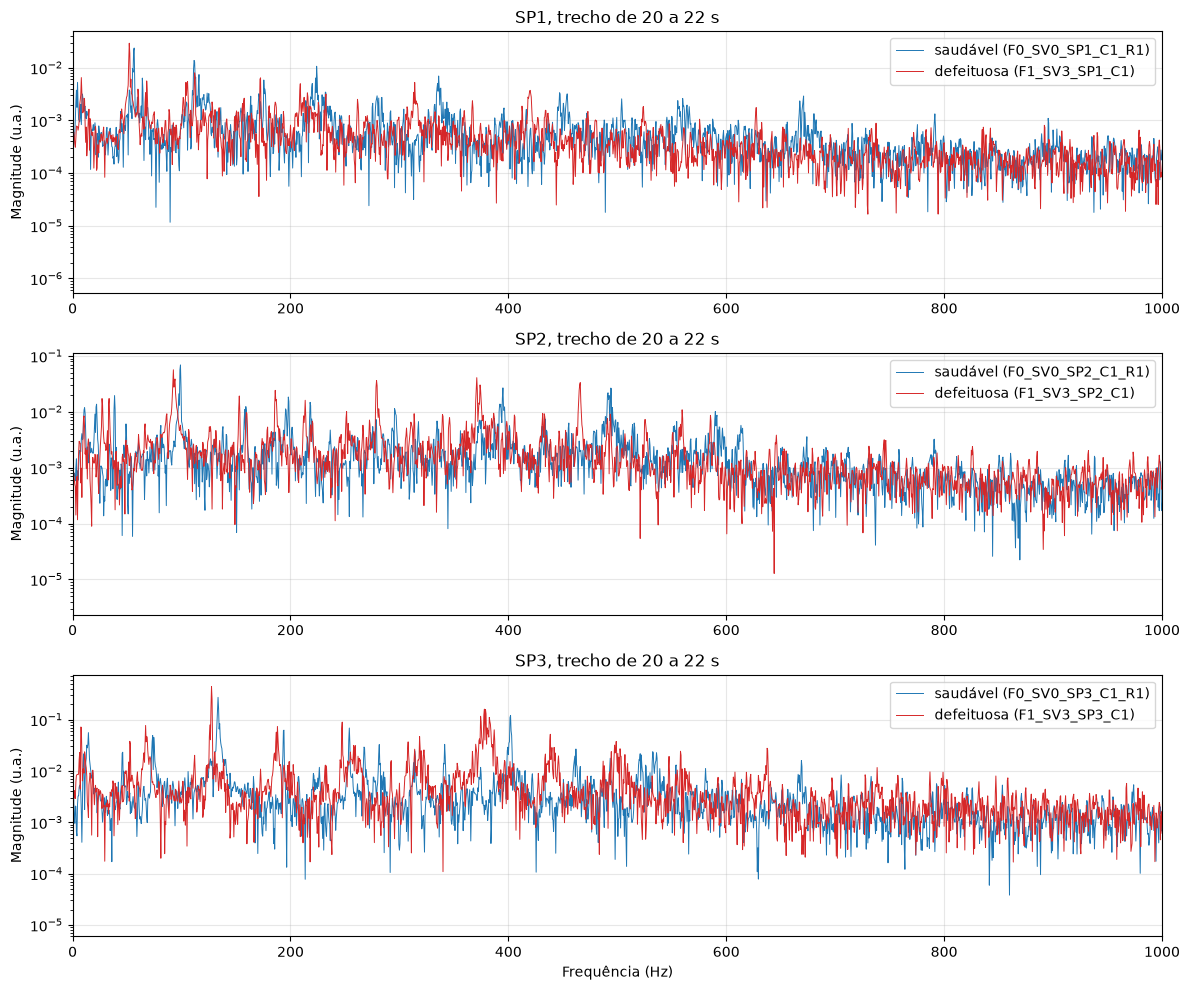

In [4]:
fig, axs = plt.subplots(3, 1, figsize=(12, 10))
for ax, sp in zip(axs, ARQ):
    for cond in ["saudavel", "defeituoso"]:
        ax.semilogy(f, espectros[(sp, cond)], lw=0.7, color=CORES[cond],
                    label=f"{ROT[cond]} ({ARQ[sp][cond][:-4]})")
    ax.set_xlim(0, 1000)
    ax.set_ylabel("Magnitude (u.a.)")
    ax.set_title(f"SP{sp}, trecho de 20 a 22 s")
    ax.grid(alpha=0.3)
    ax.legend(loc="upper right")
axs[-1].set_xlabel("Frequência (Hz)")
plt.tight_layout()
plt.savefig("../results/figures/espectros_par_sp.png", dpi=150)
plt.show()

In [5]:
def top_picos(mag, n=5):
    # picos locais separados por 5 Hz (10 bins), acima de 10 Hz
    idx, _ = find_peaks(mag, distance=10)
    idx = idx[f[idx] >= 10]
    # fica com os n maiores, em ordem de frequência
    return np.sort(idx[np.argsort(mag[idx])[::-1][:n]])


# f1: maior magnitude entre 30 e 200 Hz, buscada só nessa faixa
b = (f >= 30) & (f <= 200)

linhas = []
for (sp, cond), mag in espectros.items():
    f1 = f[b][mag[b].argmax()]
    for i in top_picos(mag):
        linhas.append({"SP": sp, "condição": ROT[cond], "f (Hz)": f[i],
                       "magnitude (u.a.)": mag[i], "f/f1": f[i] / f1})
print(pd.DataFrame(linhas).round({"f (Hz)": 1, "magnitude (u.a.)": 4, "f/f1": 2}).to_string(index=False))

 SP   condição  f (Hz)  magnitude (u.a.)  f/f1
  1   saudável    56.5            0.0236  1.00
  1   saudável    64.0            0.0064  1.13
  1   saudável   111.5            0.0137  1.97
  1   saudável   224.0            0.0107  3.96
  1   saudável   336.0            0.0070  5.95
  1 defeituosa    52.0            0.0292  1.00
  1 defeituosa    68.0            0.0056  1.31
  1 defeituosa   105.5            0.0055  2.03
  1 defeituosa   112.0            0.0080  2.15
  1 defeituosa   172.5            0.0064  3.32
  2   saudável    38.5            0.0196  0.39
  2   saudável    99.0            0.0691  1.00
  2   saudável   198.0            0.0184  2.00
  2   saudável   395.0            0.0268  3.99
  2   saudável   494.0            0.0266  4.99
  2 defeituosa    92.5            0.0566  1.00
  2 defeituosa   186.0            0.0242  2.01
  2 defeituosa   279.0            0.0362  3.02
  2 defeituosa   371.0            0.0409  4.01
  2 defeituosa   466.0            0.0334  5.04
  3   saudáve

## Espectro médio por condição e SP

Média das magnitudes de todas as janelas (480 saudáveis e 1890 defeituosas), em escala log até 5000 Hz. Serve para escolher as bandas de frequência.

In [6]:
# espectro de todas as janelas, alinhado com as linhas de list_janelas
mag_all = np.zeros((len(list_janelas), len(f)))
for arquivo, g in list_janelas.groupby("arquivo"):
    mag_all[g.index] = espectro(get_matriz_acc(arquivo, list_janelas), FS)[1]
print(mag_all.shape)

(2370, 10001)


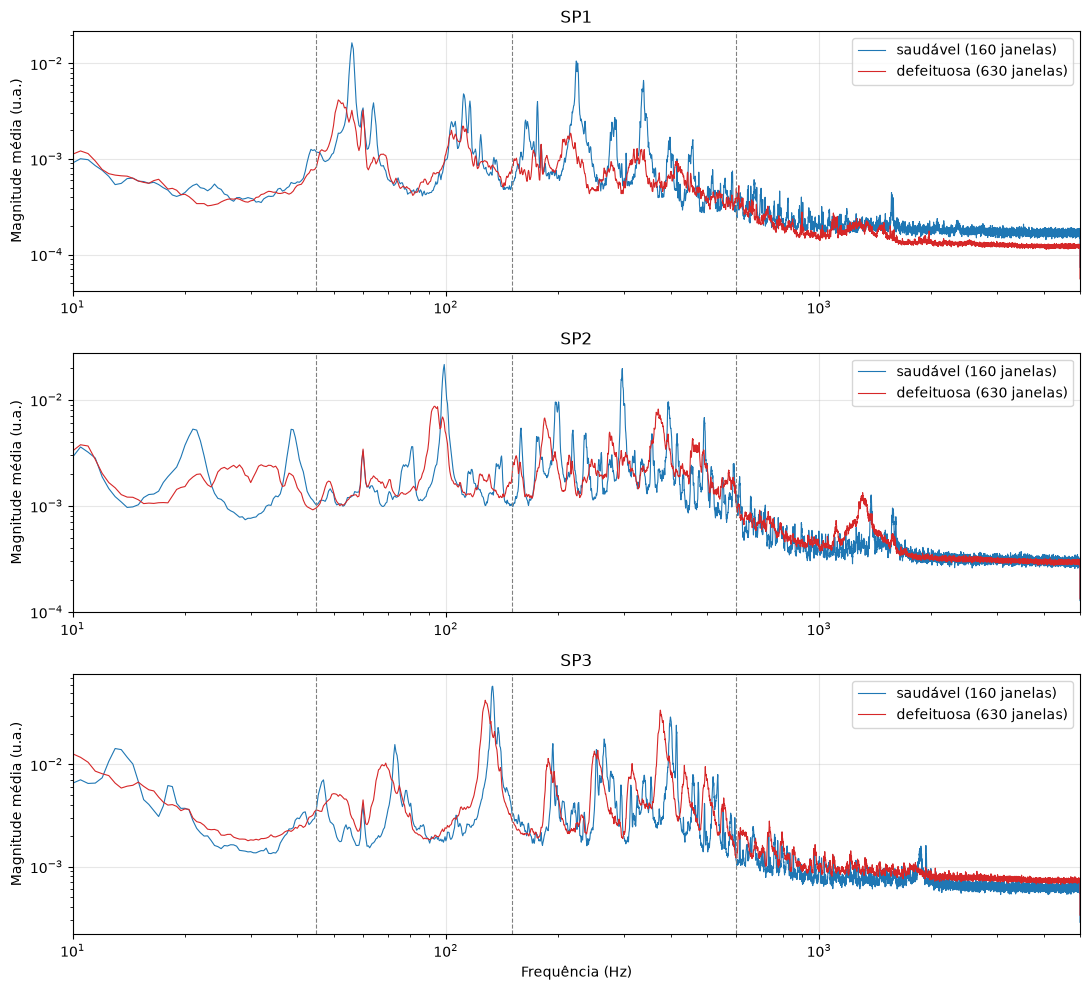

In [ ]:
# O eixo logarítmico só aceita frequências positivas.
frequencias = f[1:]

# Um painel para cada SP.
fig, axs = plt.subplots(3, 1, figsize=(11, 10))
for ax, sp in zip(axs, ARQ):
    mesmo_sp = list_janelas["SP"] == sp

    # Separa as janelas saudáveis das defeituosas.
    for cond, nome in ROT.items():
        mesma_condicao = list_janelas["rotulo"] == cond
        magnitudes_grupo = mag_all[mesmo_sp & mesma_condicao]

        # Cada coluna é uma frequência. A média junta as janelas dessa coluna.
        magnitude_media = magnitudes_grupo.mean(axis=0)
        legenda = f"{nome} ({len(magnitudes_grupo)} janelas)"
        ax.loglog(frequencias, magnitude_media[1:], lw=0.8,
                  color=CORES[cond], label=legenda)

    # O gráfico começa em 10 Hz. marca o início das outras bandas.
    for banda in BANDAS[1:]:
        inicio = banda[0]
        ax.axvline(inicio, ls="--", color="gray", lw=0.8)

    ax.set_xlim(10, FS / 2)
    ax.set_ylabel("Magnitude média (u.a.)")
    ax.set_title(f"SP{sp}")
    ax.grid(alpha=0.3)
    ax.legend(loc="upper right")
axs[-1].set_xlabel("Frequência (Hz)")
plt.tight_layout()
plt.savefig("../results/figures/espectros_medios_sp.png", dpi=150)
plt.show()

## Bandas e características espectrais

Bandas escolhidas olhando o espectro médio (linhas tracejadas), as mesmas para todos os SP e condições:

- **10 a 45 Hz**: abaixo do maior pico do SP1 (≈ 52 a 57 Hz), pouca energia no espectro médio;
- **45 a 150 Hz**: contém o maior pico (`f1`) dos três SP (≈ 52 a 133 Hz);
- **150 a 600 Hz**: picos depois de `f1` e queda do espectro;
- **600 a 5000 Hz**: dominado por ruído, de ~600 a 800 Hz.


In [8]:
# características de todas as janelas, com as colunas de identificação de feat_t
feat_f = pd.DataFrame(feat_espectrais(f, mag_all))
feat_f = pd.concat([list_janelas[["arquivo", "id", "rotulo", "F", "SV", "SP", "C", "jan"]], feat_f], axis=1)

cols_pot = [c for c in feat_f if c.startswith("pot_")]
assert len(feat_f) == len(list_janelas)
assert feat_f.isna().sum().sum() == 0
# as bandas cobrem f >= 10 Hz, então a soma delas é a potência total
assert np.allclose(feat_f[cols_pot].sum(axis=1), (mag_all[:, f >= 10] ** 2).sum(axis=1))

feat_f.to_csv("../data/processed/features_freq.csv", index=False)
print(feat_f.shape)

(2370, 16)


In [9]:
cols = ["f_dom", "mag_pico"] + cols_pot + ["centroide", "entropia"]
g = feat_f.groupby(["SP", "rotulo"])[cols]
fmt = "{:.3g}".format

print("mediana")
print(g.median().to_string(float_format=fmt))
print("\nIQR (q75 - q25)")
print((g.quantile(0.75) - g.quantile(0.25)).to_string(float_format=fmt))

# fração de janelas com f_dom acima de 200 Hz (acima do f1 de todos os SP)
print("\nfração de janelas com f_dom > 200 Hz")
print((feat_f["f_dom"] > 200).groupby([feat_f["SP"], feat_f["rotulo"]]).mean().round(2).to_string())

mediana
               f_dom  mag_pico  pot_10_45  pot_45_150  pot_150_600  pot_600_5000  centroide  entropia
SP rotulo                                                                                            
1  defeituoso     56    0.0125   2.87e-05    0.000558     0.000824      0.000254        477     0.639
   saudavel     56.8    0.0247   2.96e-05     0.00177      0.00148       0.00046        376     0.558
2  defeituoso    363    0.0458   0.000396     0.00297       0.0189       0.00258        458     0.579
   saudavel      248    0.0501    0.00054     0.00382       0.0144       0.00251        402     0.548
3  defeituoso    136     0.164     0.0014      0.0542       0.0951       0.00808        373     0.477
   saudavel      396     0.128     0.0025      0.0398       0.0709       0.00679        396     0.433

IQR (q75 - q25)
               f_dom  mag_pico  pot_10_45  pot_45_150  pot_150_600  pot_600_5000  centroide  entropia
SP rotulo                                                

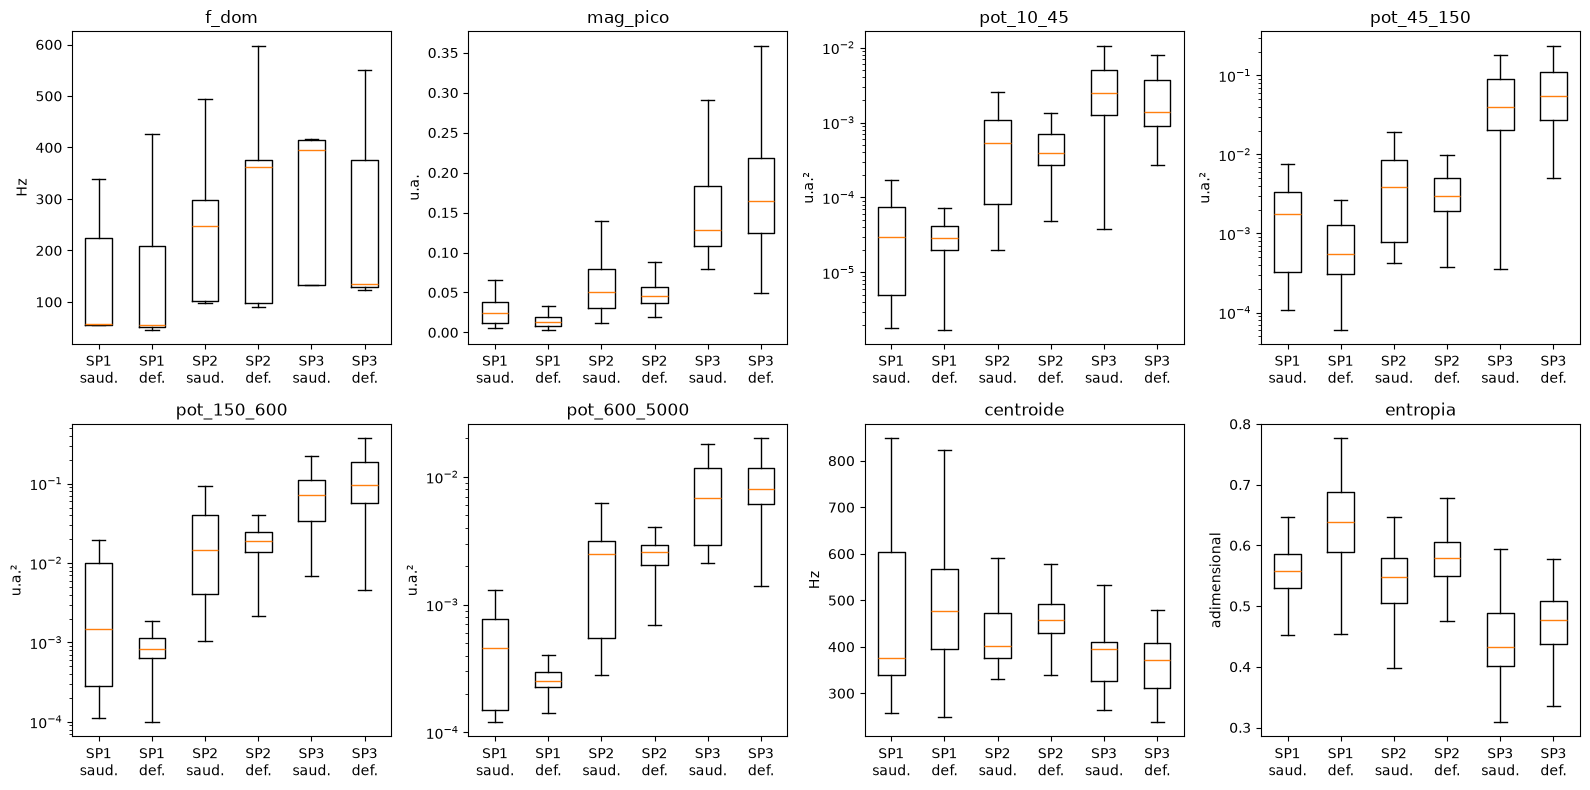

In [10]:
condicoes = [("saudavel", "saud."), ("defeituoso", "def.")]

# Um painel para cada característica.
fig, axs = plt.subplots(2, 4, figsize=(16, 8))
for ax, caracteristica in zip(axs.ravel(), cols):
    dados = []
    rotulos = []

    # Uma caixa para cada combinação de SP e condição.
    for sp in [1, 2, 3]:
        mesmo_sp = feat_f["SP"] == sp
        for condicao, nome_curto in condicoes:
            mesma_condicao = feat_f["rotulo"] == condicao
            valores = feat_f.loc[mesmo_sp & mesma_condicao, caracteristica]
            dados.append(valores)
            rotulos.append(f"SP{sp}\n{nome_curto}")

    ax.boxplot(dados, tick_labels=rotulos, showfliers=False)
    ax.set_title(caracteristica)

    # As potências variam muito e usam escala logarítmica.
    if caracteristica in cols_pot:
        ax.set_yscale("log")
        ax.set_ylabel("u.a.²")
    elif caracteristica in ["f_dom", "centroide"]:
        ax.set_ylabel("Hz")
    elif caracteristica == "mag_pico":
        ax.set_ylabel("u.a.")
    elif caracteristica == "entropia":
        ax.set_ylabel("adimensional")

plt.tight_layout()
plt.savefig("../results/figures/boxplots_freq.png", dpi=150)
plt.show()